In [13]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Challenge2_nuova"
%cd $current_dir

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/My Drive/Challenge2_nuova


In [25]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph
from tqdm.notebook import tqdm

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
PyTorch version: 2.9.0+cu126
Device: cuda


## ⏳ **Data Loading** & 🔄 **Data Preprocessing**



In [31]:
# @title **Part 1: Data Preparation & Patching**
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import shutil
from sklearn.model_selection import train_test_split

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "challenge_data/train_data"
LABELS_CSV_PATH = "challenge_data/train_labels.csv"
TARGET_DATA_DIR = "dataset_filtered_patched_fra2"

# Patching Parameters
PATCH_SIZE = 224
STRIDE = 140


# 1% Threshold (Permissive to avoid losing Triple Negative)
TISSUE_THRESHOLD_RATIO = 0.01

# --- BLACKLIST (Corrupted images to ignore) ---
IMGS_TO_REMOVE = [1, 5, 8, 12, 18, 20, 22, 25, 27, 28, 36, 47, 48, 52,
                        62, 78, 85, 90, 94, 95, 126, 129, 130, 133, 136, 138,
                        148, 150, 155, 159, 161, 175, 178, 179, 180, 187, 189, 193, 196, 222, 237,
                        251, 253, 254, 263, 268, 270, 286, 293, 313, 319, 333, 342, 344, 346, 355,
                        368, 371, 376, 380, 390, 393, 407, 410, 415, 424, 440, 443, 453, 459, 463,
                        486, 497, 498, 499, 509, 521, 530, 531, 533, 537, 540, 544, 547, 557, 558,
                        560, 565, 567, 572, 576, 578, 580, 586, 602, 603, 607, 609, 614, 620, 623,
                        629, 635, 639, 643, 644, 645, 646, 656, 657, 658, 670, 673, 675]

def remove_artifacts_final_v3(image_rgb):
    """
    Version v3 (Differentiated):
    - BLUE/BLACK: Conservative removal (Only large areas > 2000 px) to protect nuclei.
    - GREEN/CYAN: Aggressive removal (Also small areas > 100 px) because it's an alien color.
    """
    result = image_rgb.copy()

    # Pre-processing (Light blur to homogenize liquid colors)
    blurred = cv2.GaussianBlur(image_rgb, (5,5), 0)
    hsv = cv2.cvtColor(blurred, cv2.COLOR_RGB2HSV)

    # --- GROUP 1: THE “FALSE FRIENDS” (Blue/Black that resemble nuclei) ---
    lower_blue = np.array([90, 50, 50]); upper_blue = np.array([130, 255, 255])
    mask_blue = cv2.inRange(hsv, lower_blue, upper_blue)

    lower_dark = np.array([0, 0, 0]); upper_dark = np.array([180, 255, 60])
    mask_dark = cv2.inRange(hsv, lower_dark, upper_dark)

    mask_risk_group = cv2.bitwise_or(mask_blue, mask_dark)

    # --- GROUP 2: THE “ALIENS” (Fluorescent Green / Cyan) ---
    # Toxic Green (High saturation)
    lower_toxic = np.array([35, 150, 150]); upper_toxic = np.array([85, 255, 255])
    mask_toxic = cv2.inRange(hsv, lower_toxic, upper_toxic)

    # Cyan/Teal (Translucent)
    lower_teal = np.array([80, 50, 100]); upper_teal = np.array([100, 255, 255])
    mask_teal = cv2.inRange(hsv, lower_teal, upper_teal)

    mask_alien_group = cv2.bitwise_or(mask_toxic, mask_teal)

    # --- DIFFERENTIATED REMOVAL LOGIC ---
    mask_to_remove = np.zeros_like(mask_risk_group)

    # Process the Risk Group (Blue/Black) -> HIGH THRESHOLD
    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask_risk_group, connectivity=8)
    SAFE_THRESHOLD_BLUE = 1500  # Must be very large to be removed

    for i in range(1, num):
        if stats[i, cv2.CC_STAT_AREA] > SAFE_THRESHOLD_BLUE:
            mask_to_remove[labels == i] = 255

    # Process the Alien Group (Green/Cyan) -> LOW THRESHOLD
    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask_alien_group, connectivity=8)
    AGGRESSIVE_THRESHOLD_GREEN = 100  # If it's visible, it's removed

    for i in range(1, num):
        if stats[i, cv2.CC_STAT_AREA] > AGGRESSIVE_THRESHOLD_GREEN:
            mask_to_remove[labels == i] = 255

    # --- FINAL CLEANUP ---
    # Dilation to cover halos
    kernel = np.ones((5,5), np.uint8)
    mask_to_remove = cv2.dilate(mask_to_remove, kernel, iterations=3)

    # Replacement
    result[mask_to_remove > 0] = [235, 235, 235]

    return result

def create_patches_pipeline(source_dir, target_dir, csv_path, train_ratio=0.85):
    source_path = Path(source_dir)
    target_path = Path(target_dir)

    # 1. Load Labels
    print("Loading labels...")
    try:
        df_labels = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Error loading CSV: {e}")
        return

    # Map labels to numeric for stratification
    unique_labels = df_labels.iloc[:, 1].astype('category').cat.codes
    label_to_numeric = dict(zip(df_labels.iloc[:, 1], unique_labels))
    numeric_to_label = dict(zip(unique_labels, df_labels.iloc[:, 1]))

    # Filter out blacklisted images and prepare for split
    filtered_images = []
    filtered_labels_numeric = []
    for _, row in df_labels.iterrows():
        img_name = row.iloc[0]
        file_id = int(img_name.replace('img_', '').replace('.png', ''))
        if file_id not in IMGS_TO_REMOVE:
            filtered_images.append(img_name)
            filtered_labels_numeric.append(label_to_numeric[row.iloc[1]])

    print(f"Total images after blacklist filtering: {len(filtered_images)}")

    # 2. Stratified Train-Validation Split on original image IDs
    train_image_names, val_image_names, train_numeric_labels, val_numeric_labels = train_test_split(
        filtered_images, filtered_labels_numeric,
        train_size=train_ratio,
        stratify=filtered_labels_numeric,
        random_state=SEED
    )

    print(f"Train images: {len(train_image_names)}")
    print(f"Validation images: {len(val_image_names)}")

    # Reconstruct label maps for convenience during patch saving
    train_labels_map = {img_name: numeric_to_label[label_num] for img_name, label_num in zip(train_image_names, train_numeric_labels)}
    val_labels_map = {img_name: numeric_to_label[label_num] for img_name, label_num in zip(val_image_names, val_numeric_labels)}

    # 3. Reset Output Directory and Create Train/Val Subdirectories
    if target_path.exists():
        shutil.rmtree(target_path)
    target_path.mkdir(parents=True, exist_ok=True)

    train_target_path = target_path / "train"
    val_target_path = target_path / "val"
    train_target_path.mkdir(parents=True, exist_ok=True)
    val_target_path.mkdir(parents=True, exist_ok=True)

    # 4. Processing Loop for Train and Validation
    def process_images(image_names_list, labels_map_dict, current_target_dir):
        count_saved = 0
        for img_name in tqdm(image_names_list, desc=f"Processing {current_target_dir.name} images"):
            label = labels_map_dict.get(img_name)
            if label is None:
                continue # Should not happen with current logic

            # --- FOLDER CREATION ---
            safe_label = str(label).replace(" ", "_").replace("(", "").replace(")", "").replace("+", "plus")
            class_dir = current_target_dir / safe_label
            class_dir.mkdir(parents=True, exist_ok=True)

            img_path = source_path / img_name

            # --- IMAGE LOAD ---
            image = cv2.imread(str(img_path))
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # RGB 3 channels

            # --- MASK LOAD (Only for filtering) ---
            mask_path = source_path / f"mask_{Path(img_name).stem.replace('img_', '')}.png"
            mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) if mask_path.exists() else None

            h, w, _ = image.shape
            if h < PATCH_SIZE or w < PATCH_SIZE:
                continue

            # --- TILING ---
            p_idx = 0
            for y in range(0, h - PATCH_SIZE + 1, STRIDE):
                for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                    patch = image[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

                    # Cleaning of the image
                    # patch_clean = remove_artifacts_final_v3(patch)

                    # Validity Logic (Mask OR White-heuristic)
                    is_valid = False
                    if mask is not None:
                        patch_mask = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                        if (np.sum(patch_mask > 0) / (PATCH_SIZE**2)) > TISSUE_THRESHOLD_RATIO:
                            is_valid = True
                    else:
                        gray = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)
                        if (np.sum(gray > 220) / (PATCH_SIZE**2)) < 0.99:
                            is_valid = True


                    if is_valid:
                        cv2.imwrite(
                            str(class_dir / f"{Path(img_name).stem}_p{p_idx}.png"),
                            cv2.cvtColor(patch, cv2.COLOR_RGB2BGR)
                        )
                        count_saved += 1
                        p_idx += 1
        return count_saved

    total_train_patches = process_images(train_image_names, train_labels_map, train_target_path)
    total_val_patches = process_images(val_image_names, val_labels_map, val_target_path)

    print(f"\nDone! Saved {total_train_patches} training patches and {total_val_patches} validation patches.")

# Call the updated pipeline function
create_patches_pipeline(SOURCE_DATA_DIR, TARGET_DATA_DIR, LABELS_CSV_PATH, train_ratio=0.85)


Loading labels...
Total images after blacklist filtering: 577
Train images: 490
Validation images: 87


Processing val images: 100%|██████████| 87/87 [00:12<00:00,  7.23it/s]


Done! Saved 6394 training patches and 982 validation patches.


##  💪 **Image Augmentation** / 🧮 **Network Parameters** / 🧠 **Training Functions**

In [32]:

import torch
import torch.nn as nn
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import ReduceLROnPlateau

# --- 1. DATA AUGMENTATION PIPELINE ---
# Histology-specific augmentation pipeline (Training)
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(180),
    transforms.RandomApply([transforms.ElasticTransform(alpha=50.0, sigma=5.0)], p=0.2),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 1.25))], p=0.2),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1)], p=0.5),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Base pipeline (Validation)
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- 2. DATASET LOADING & SPLIT ---
data_dir = "dataset_filtered_patched_fra"  # Make sure this folder exists

# Load datasets directly from 'train' and 'val' subdirectories
train_dataset = datasets.ImageFolder(root=Path(data_dir) / "train")
val_dataset_raw = datasets.ImageFolder(root=Path(data_dir) / "val") # Suffix _raw for original ImageFolder

print(f"Classes found: {train_dataset.classes}")

# --- 3. HELPER DATASET CLASSES ---
class TransformDataset(torch.utils.data.Dataset):
    """Applies transformations to an ImageFolder dataset."""
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.dataset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.dataset)

class TransformDatasetWithOriginalID(torch.utils.data.Dataset):
    """Also returns the original image ID for aggregation during validation."""
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index):
        original_img_pil, label_idx = self.dataset[index]

        # Retrieve original path from the underlying dataset (ImageFolder)
        img_path, _ = self.dataset.samples[index]

        # Extract the ID (e.g., from 'dataset_patched/Luminal/img_100_p0.png' -> 'img_100')
        original_img_id = Path(img_path).stem.split('_p')[0]

        if self.transform:
            transformed_img = self.transform(original_img_pil)
        else:
            transformed_img = transforms.ToTensor()(original_img_pil)

        return transformed_img, label_idx, original_img_id

    def __len__(self):
        return len(self.dataset)

# Create final datasets
train_data = TransformDataset(train_dataset, transform=train_transforms)
val_data = TransformDatasetWithOriginalID(val_dataset_raw, transform=val_transforms)

# Create DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training patches: {len(train_data)}")
print(f"Validation patches: {len(val_data)}")

# --- 4. TRAINING SETUP (Loss & Weights) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Compute class weights using only the training dataset's targets
y_train_indices = train_dataset.targets
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_indices),
    y=y_train_indices
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

print("\nClass Weights:", class_weights_tensor)

# Loss Function (Single definition!)
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=0.1
)

# Hyperparameters
LEARNING_RATE = 1e-4  # Lowered for stable fine-tuning
EPOCHS = 40
PATIENCE = 10
DROPOUT_RATE = 0.5

# --- 5. TRAINING FUNCTIONS ---
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    all_preds, all_targets = [], []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    epoch_f1 = f1_score(all_targets, all_preds, average='weighted')

    return epoch_loss, epoch_acc, epoch_f1

def validate_one_epoch(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0

    # Dictionaries for aggregation
    img_votes = {}  # {img_id: [vote1, vote2...]}}
    img_labels = {}  # {img_id: ground_truth_label}

    with torch.no_grad():
        for inputs, targets, img_ids in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            preds = logits.argmax(dim=1).cpu().numpy()
            targets_np = targets.cpu().numpy()

            # Vote aggregation
            for i, img_id in enumerate(img_ids):
                if img_id not in img_votes:
                    img_votes[img_id] = []
                    img_labels[img_id] = targets_np[i]
                img_votes[img_id].append(preds[i])

    # Compute aggregated metrics (Slide-Level)
    final_preds, final_targets = [], []
    for img_id in img_votes:
        votes = img_votes[img_id]
        # Majority Voting
        winner = np.bincount(votes).argmax()
        final_preds.append(winner)
        final_targets.append(img_labels[img_id])

    slide_acc = accuracy_score(final_targets, final_preds)
    slide_f1 = f1_score(final_targets, final_preds, average='weighted')
    patch_loss = running_loss / len(val_loader.dataset)

    return patch_loss, slide_acc, slide_f1

def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, experiment_name="exp"):

    writer = SummaryWriter(f"logs/{experiment_name}")
    best_f1 = 0.0
    patience_counter = 0

    # Initialize history dictionary
    history = {
        'train_loss': [],
        'train_acc': [],
        'train_f1': [],
        'val_loss': [],
        'val_acc': [],
        'val_f1': []
    }

    # --- SCHEDULER ---
    # If the Validation Loss doesn't drop for 5 epochs, then divide the LR by 2
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    print(f"\nStarting training for {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        t_loss, t_acc, t_f1 = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        v_loss, v_acc, v_f1 = validate_one_epoch(model, val_loader, criterion, device)

        # Store metrics in history
        history['train_loss'].append(t_loss)
        history['train_acc'].append(t_acc)
        history['train_f1'].append(t_f1)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        history['val_f1'].append(v_f1)

        # Log current Learning Rate
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch:03d} | Train Loss: {t_loss:.4f} F1: {t_f1:.4f} | Val Loss: {v_loss:.4f} F1: {v_f1:.4f} (Slide-Level)")

        writer.add_scalar('Acc/Train', t_acc, epoch)
        writer.add_scalar('Acc/Val', v_acc, epoch)
        writer.add_scalar('Loss/Train', t_loss, epoch)
        writer.add_scalar('Loss/Val', v_loss, epoch)
        writer.add_scalar('F1/Train', t_f1, epoch)
        writer.add_scalar('F1/Val', v_f1, epoch)

        scheduler.step(v_loss)

        # Early Stopping on Validation Accuracy (Slide-Level)
        if v_f1 > best_f1:
            best_f1 = v_f1
            patience_counter = 0
            torch.save(model.state_dict(), f"models/{experiment_name}_best.pt")
            print("  --> Model Saved!")
        else:
            patience_counter += 1
            if patience > 0 and patience_counter >= patience:
                print("  --> Early Stopping!")
                break

    writer.close()
    return model, history # Return both model and history

Classes found: ['HER2plus', 'Luminal_A', 'Luminal_B', 'Triple_negative']
Training patches: 19864
Validation patches: 3386

Class Weights: tensor([1.0102, 0.9470, 0.6846, 2.0269], device='cuda:0')


## 🛠️ **Transfer Learning** & 🛠️ **Fine-Tuning**

In [33]:
# @title **Part 3: Model Definition & Training**

import torch
import torch.nn as nn
import torchvision
from torchsummary import summary
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# --- MODEL DEFINITION (ConvNeXt) ---
class ConvNextTransferLearning(nn.Module):
    """ConvNeXt_Tiny adapted for transfer learning."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # Load ConvNeXt Tiny backbone
        self.backbone = torchvision.models.convnext_tiny(
            weights=torchvision.models.ConvNeXt_Tiny_Weights.DEFAULT
        )

        # Freeze backbone
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # Replace Classifier Head
        # The original structure: backbone.classifier[2] is the final Linear layer
        in_features = self.backbone.classifier[2].in_features

        self.backbone.classifier[2] = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

    def unfreeze_last_stage(self):
        """Unfreeze the last stage (Stage 4) for fine-tuning."""
        # In ConvNeXt Tiny, features[7] is the last convolutional stage
        for param in self.backbone.features[7].parameters():
            param.requires_grad = True
        print("Info: Last stage (features[7]) unfrozen for training.")

In [34]:
# --- CONFIGURATION & INITIAL TRAINING (Warmup) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_shape = (3, 224, 224)

# Model Instance
num_classes = 4
model = ConvNextTransferLearning(
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    freeze_backbone=True
).to(device)

# Optimizer & Scaler
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [35]:
# Start Training (Transfer Learning - Head Only)
print(f"--- PHASE 1: Transfer Learning (Head Only) ---")
experiment_name = "FRA_Consegna"

model, history_tl = fit(
    model=model,
    train_loader=train_loader, # Using loaders from Part 2
    val_loader=val_loader,
    epochs=10, # Few epochs to stabilize the head
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    patience=5, # Aggressive early stopping
    experiment_name=experiment_name
)

best_model_path = f"models/{experiment_name}_best.pt" # experiment_name of the first phase
model.load_state_dict(torch.load(best_model_path))
print(f"✅ Pesi migliori ricaricati da: {best_model_path}")

--- PHASE 1: Transfer Learning (Head Only) ---

Starting training for 10 epochs...
Epoch 001 | Train Loss: 1.4182 F1: 0.3138 | Val Loss: 1.4076 F1: 0.2667 (Slide-Level)
  --> Model Saved!
Epoch 002 | Train Loss: 1.4021 F1: 0.3254 | Val Loss: 1.4281 F1: 0.2625 (Slide-Level)
Epoch 003 | Train Loss: 1.3978 F1: 0.3303 | Val Loss: 1.4331 F1: 0.1824 (Slide-Level)
Epoch 004 | Train Loss: 1.3994 F1: 0.3314 | Val Loss: 1.4534 F1: 0.2537 (Slide-Level)
Epoch 005 | Train Loss: 1.3979 F1: 0.3291 | Val Loss: 1.3840 F1: 0.3297 (Slide-Level)
  --> Model Saved!
Epoch 006 | Train Loss: 1.4013 F1: 0.3278 | Val Loss: 1.4092 F1: 0.2885 (Slide-Level)
Epoch 007 | Train Loss: 1.3994 F1: 0.3262 | Val Loss: 1.3846 F1: 0.3496 (Slide-Level)
  --> Model Saved!
Epoch 008 | Train Loss: 1.4012 F1: 0.3279 | Val Loss: 1.4565 F1: 0.1683 (Slide-Level)
Epoch 009 | Train Loss: 1.3975 F1: 0.3213 | Val Loss: 1.3765 F1: 0.3591 (Slide-Level)
  --> Model Saved!
Epoch 010 | Train Loss: 1.3993 F1: 0.3288 | Val Loss: 1.4024 F1: 0.

In [36]:
# --- FINE-TUNING (Partial Unfreezing) ---
print(f"\n--- PHASE 2: Fine-Tuning (Last Stage Unfrozen) ---")

# Unfreeze the last block
model.unfreeze_last_stage()

# Reinitialize Optimizer with differentiated LR (Low for backbone, Medium for head)
# The head is in model.backbone.classifier[2]
# Last stage is in model.backbone.features[7]
params_backbone = list(model.backbone.features[7].parameters())
params_head = list(model.backbone.classifier[2].parameters())

optimizer_ft = torch.optim.Adam([
    {'params': params_head, 'lr': 1e-4},      # Head: medium LR
    {'params': params_backbone, 'lr': 1e-5}   # Backbone: low LR
], weight_decay=1e-4) # Regularization

experiment_name_ft = "FRA_consegna_ft"


--- PHASE 2: Fine-Tuning (Last Stage Unfrozen) ---
Info: Last stage (features[7]) unfrozen for training.


In [37]:
# Start Full Training
model, history_ft = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=500, # Total epochs
    criterion=criterion,
    optimizer=optimizer_ft, # New optimizer
    scaler=scaler,
    device=device,
    patience=20,
    experiment_name=experiment_name_ft
)


Starting training for 500 epochs...
Epoch 001 | Train Loss: 1.3761 F1: 0.3376 | Val Loss: 1.3851 F1: 0.3468 (Slide-Level)
  --> Model Saved!
Epoch 002 | Train Loss: 1.3596 F1: 0.3442 | Val Loss: 1.3851 F1: 0.3707 (Slide-Level)
  --> Model Saved!
Epoch 003 | Train Loss: 1.3550 F1: 0.3492 | Val Loss: 1.3788 F1: 0.3806 (Slide-Level)
  --> Model Saved!
Epoch 004 | Train Loss: 1.3480 F1: 0.3480 | Val Loss: 1.3852 F1: 0.3654 (Slide-Level)
Epoch 005 | Train Loss: 1.3403 F1: 0.3589 | Val Loss: 1.3797 F1: 0.4037 (Slide-Level)
  --> Model Saved!
Epoch 006 | Train Loss: 1.3390 F1: 0.3623 | Val Loss: 1.3835 F1: 0.3514 (Slide-Level)
Epoch 007 | Train Loss: 1.3269 F1: 0.3710 | Val Loss: 1.3818 F1: 0.3806 (Slide-Level)
Epoch 008 | Train Loss: 1.3247 F1: 0.3687 | Val Loss: 1.3861 F1: 0.3838 (Slide-Level)
Epoch 009 | Train Loss: 1.3201 F1: 0.3795 | Val Loss: 1.3899 F1: 0.3040 (Slide-Level)
Epoch 010 | Train Loss: 1.3143 F1: 0.3794 | Val Loss: 1.3817 F1: 0.3606 (Slide-Level)
Epoch 011 | Train Loss: 1.3


Computing final Confusion Matrix (Slide Level)...


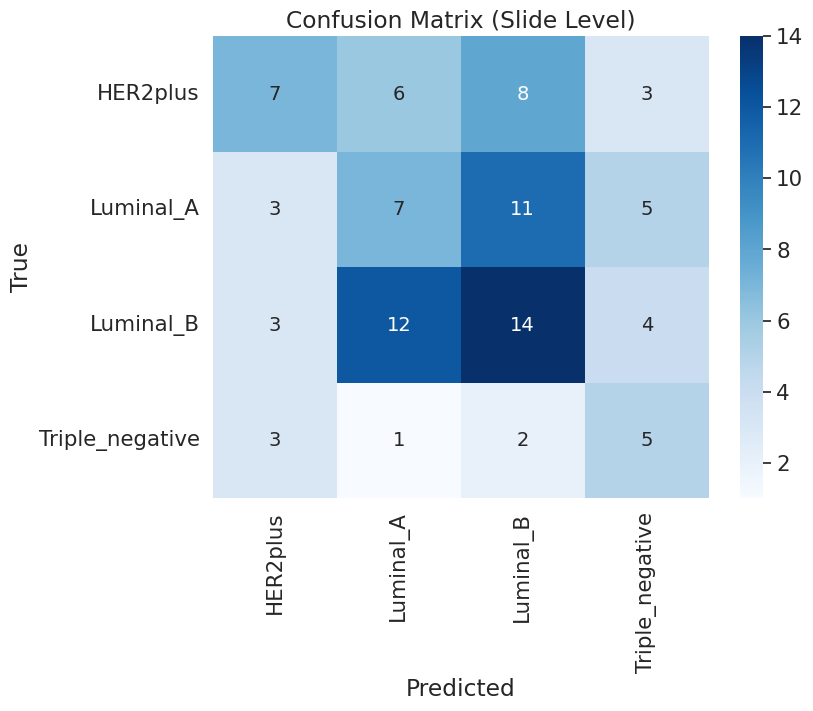

In [38]:
# Confusion Matrix (Aggregated)
print("\nComputing final Confusion Matrix (Slide Level)...")
model.eval()
all_preds, all_labels = [], []
img_votes, img_labels = {}, {}

with torch.no_grad():
    for inputs, targets, img_ids in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        targets = targets.numpy()

        for i, img_id in enumerate(img_ids):
            if img_id not in img_votes:
                img_votes[img_id] = []
                img_labels[img_id] = targets[i]
            img_votes[img_id].append(preds[i])

for img_id in img_votes:
    final_pred = np.bincount(img_votes[img_id]).argmax()
    all_preds.append(final_pred)
    all_labels.append(img_labels[img_id])

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=val_dataset_raw.classes, yticklabels=val_dataset_raw.classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Slide Level)')
plt.show()

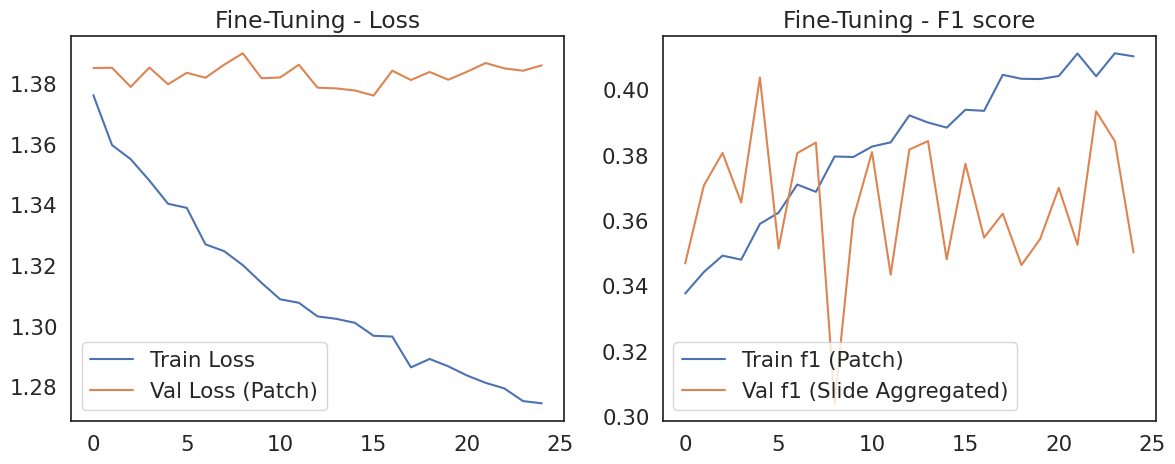

In [39]:
# --- RESULTS VISUALIZATION ---
# Plot History (Combine or plot only the last one)
def plot_history(history, title="Training History"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    ax1.plot(history['train_loss'], label='Train Loss')
    ax1.plot(history['val_loss'], label='Val Loss (Patch)')
    ax1.set_title(f'{title} - Loss')
    ax1.legend()

    # F1 score
    ax2.plot(history['train_f1'], label='Train f1 (Patch)')
    ax2.plot(history['val_f1'], label='Val f1 (Slide Aggregated)')
    ax2.set_title(f'{title} - F1 score')
    ax2.legend()
    plt.show()

plot_history(history_ft, "Fine-Tuning")

## **🔄 Test Time Augmentation (TTA)**

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from collections import Counter

# --- CONFIGURATION ---
TEST_DATA_DIR = "challenge_data/test_data"  # Path to original test images
MODEL_PATH = "models/FRA_consegna_ft_best.pt"  # Your saved model
SUBMISSION_PATH = "submission_tta_patching.csv"

# Patching Parameters (Must match the training phase)
PATCH_SIZE = 224
STRIDE = 160
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- STEP 1: TTA TRANSFORMATIONS DEFINITION ---
class TTATransforms:
    """Handles Test Time Augmentation transformations."""
    def __init__(self):
        # Base normalization (required for the network)
        self.normalize = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])

    def get_batch(self, image_pil):
        """
        Takes a PIL image and returns a batch of 3 tensors:
        [Original, H-Flip, V-Flip]
        """
        # 1. Original
        t_orig = self.normalize(image_pil)

        # 2. Horizontal Flip
        img_h = transforms.functional.hflip(image_pil)
        t_h = self.normalize(img_h)

        # 3. Vertical Flip
        img_v = transforms.functional.vflip(image_pil)
        t_v = self.normalize(img_v)

        # Stack into a single batch (3, C, H, W)
        return torch.stack([t_orig, t_h, t_v])

# --- FLEXIBLE PREDICTOR CLASS ---
class PatchTTAPredictor:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.tta = TTATransforms()
        self.model.eval()

    def predict_single_slide(self, img_path, use_masks=False):
        """
        Performs inference on a slide.
        Args:
            img_path: Path to the image.
            use_masks: If True, searches for and uses the mask for filtering.
                       If False, uses the white-color heuristic.
        """
        # Load Image
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None: return None
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Mask Handling (If requested)
        mask = None
        if use_masks:
            # Build mask filename (e.g., img_001.png -> mask_001.png)
            mask_path = img_path.parent / f"mask_{img_path.stem.replace('img_', '')}.png"
            if mask_path.exists():
                mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
            else:
                # Silent fallback: if mask is missing, should we use the heuristic later?
                # Or print a warning. For now we leave mask=None.
                pass

        h, w, _ = img_rgb.shape
        votes = []

        # Tiling Loop
        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                patch = img_rgb[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

                is_valid_patch = False

                # --- PATCH SELECTION LOGIC ---
                if mask is not None:
                    # MASK MODE
                    patch_mask = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                    # 1% threshold (consistent with training)
                    tissue_ratio = np.sum(patch_mask > 0) / (PATCH_SIZE**2)
                    if tissue_ratio > 0.01:
                        is_valid_patch = True
                else:
                    # HEURISTIC MODE (or fallback if mask is missing)
                    gray = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)
                    # Count white pixels
                    white_ratio = np.sum(gray > 220) / (PATCH_SIZE**2)
                    # If less than 99% is white, keep the patch
                    if white_ratio < 0.99:
                        is_valid_patch = True

                # --- INFERENCE ---
                if is_valid_patch:
                    patch_pil = Image.fromarray(patch)
                    batch_tensor = self.tta.get_batch(patch_pil).to(self.device)

                    with torch.no_grad():
                        logits = self.model(batch_tensor)
                        probs = F.softmax(logits, dim=1)

                    # TTA Soft Voting
                    avg_probs = torch.sum(probs, dim=0)
                    votes.append(torch.argmax(avg_probs).item())

        # --- MAJORITY VOTING (Final Aggregation) ---
        if len(votes) == 0:
            # Rare fallback: if no patch passes tissue filter,
            # take the center patch without filtering.
            center_y, center_x = h//2, w//2
            patch = img_rgb[center_y:center_y+PATCH_SIZE, center_x:center_x+PATCH_SIZE]
            batch_tensor = self.tta.get_batch(Image.fromarray(patch)).to(self.device)
            with torch.no_grad():
                probs = F.softmax(self.model(batch_tensor), dim=1)
            return torch.argmax(torch.sum(probs, dim=0)).item()

        # Return the most frequent class among all patches
        return Counter(votes).most_common(1)[0][0]

# --- MODEL CLASS REDEFINITION (Necessary to load weights) ---
# Ensure this matches the one used during training!
class ConvNeXtTransferLearning(nn.Module):
    def __init__(self, num_classes, model_name='convnext_tiny'):
        super().__init__()
        if model_name == 'convnext_tiny':
            self.backbone = models.convnext_tiny(weights=None)  # No weights needed, loaded afterward
        # Modify head
        in_features = self.backbone.classifier[2].in_features
        self.backbone.classifier[2] = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.backbone(x)

# --- MODEL REDEFINITION (CORRECT VERSION) ---
class ConvNeXtTransferLearning(nn.Module):
    def __init__(self, num_classes, model_name='convnext_tiny'):
        super().__init__()
        # Set weights to None because we will load the state_dict afterward
        self.backbone = models.convnext_tiny(weights=None)

        in_features = self.backbone.classifier[2].in_features

        # 2. STRUCTURAL FIX: Must be identical to the training structure (Sequential)
        # Even if Dropout does nothing in eval(), the layer structure MUST be present
        # to correctly load the weights.
        self.backbone.classifier[2] = nn.Sequential(
            nn.Dropout(p=0.5),  # The p-value is irrelevant in eval, but the layer must exist
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

# --- RUNNER FUNCTION ---
def run_inference_experiment(predictor, file_list, use_masks, output_csv_name, label_map):
    print(f"\n🚀 STARTING INFERENCE | Mode: {'WITH MASKS' if use_masks else 'WITHOUT MASKS (Heuristic)'}")

    predictions = []

    for img_file in tqdm(file_list):
        pred = predictor.predict_single_slide(img_file, use_masks=use_masks)
        predictions.append(pred)

    # Save CSV
    inv_map = {v: k for k, v in label_map.items()}
    pred_str = [inv_map[p] for p in predictions]

    # Sequential indices
    sample_indices = [f"img_{i:04d}.png" for i in range(len(predictions))]

    df = pd.DataFrame({'sample_index': sample_indices, 'label': pred_str})
    df.to_csv(output_csv_name, index=False)
    print(f"✅ Saved: {output_csv_name}")

    # --- INTEGRATED HEAD DISPLAY ---
    print(f"Preview of {output_csv_name}:")
    display(df.head())

    return df

In [ ]:
# --- MODEL AND DATA LOADING ---

# 1. Model Setup
model = ConvNeXtTransferLearning(num_classes=4, model_name='convnext_tiny')
try:
    model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
    print("✅ Model loaded.")
except Exception as e:
    print(f"❌ Model Error: {e}")
    raise e
model.to(DEVICE)

# 2. Predictor and File Setup
predictor = PatchTTAPredictor(model, DEVICE)
test_path = Path(TEST_DATA_DIR)

# IMPORTANT FILTER: Take only images, ignoring masks in the list
all_files = list(test_path.glob("*.*"))
test_files = sorted([f for f in all_files if f.name.startswith("img_") and f.suffix.lower() in ['.png', '.jpg', '.jpeg']])

print(f"Total files to process: {len(test_files)}")

# ⚠️ MAPPING (Always verify it matches your training!)
LABEL_MAPPING = {
    'HER2(+)': 0,
    'Luminal A': 1,
    'Luminal B': 2,
    'Triple negative': 3
}

# --- EXPERIMENT 1: WITH MASKS (Best Case) ---
df_masks = run_inference_experiment(
    predictor,
    test_files,
    use_masks=True,
    output_csv_name="submission_WITH_MASKS_4.csv",
    label_map=LABEL_MAPPING
)

# --- EXPERIMENT 2: WITHOUT MASKS (Robustness Check) ---
df_no_masks = run_inference_experiment(
    predictor,
    test_files,
    use_masks=False,
    output_csv_name="submission_NO_MASKS_4.csv",
    label_map=LABEL_MAPPING
)

# Quick comparison
diff = np.sum(df_masks['label'] != df_no_masks['label'])
print(f"\n📊 COMPARISON: The two modes differ on {diff} images out of {len(test_files)}.")

✅ Model loaded.
Total files to process: 477

🚀 STARTING INFERENCE | Mode: WITH MASKS


100%|██████████| 477/477 [01:01<00:00,  7.70it/s]

✅ Saved: submission_WITH_MASKS_3.csv
Preview of submission_WITH_MASKS_3.csv:


,sample_index,label
0,img_0000.png,Luminal A
1,img_0001.png,Luminal B
2,img_0002.png,Luminal A
3,img_0003.png,Luminal B
4,img_0004.png,Luminal B



🚀 STARTING INFERENCE | Mode: WITHOUT MASKS (Heuristic)


100%|██████████| 477/477 [03:13<00:00,  2.47it/s]

✅ Saved: submission_NO_MASKS_3.csv
Preview of submission_NO_MASKS_3.csv:


,sample_index,label
0,img_0000.png,Luminal A
1,img_0001.png,Luminal A
2,img_0002.png,Luminal A
3,img_0003.png,HER2(+)
4,img_0004.png,Triple negative



📊 COMPARISON: The two modes differ on 297 images out of 477.
